In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

bundle = joblib.load("../models/lightgbm_final.joblib")
model, features, cat_cols = bundle["model"], bundle["features"], bundle["cat_cols"]

df = pd.read_csv("../data/processed/features_v2.csv", parse_dates=["date"])
df["target"] = np.log1p(df["market_value_in_eur"])
trainval = df[df["date"] < "2025-01-01"]
test = df[df["date"] >= "2025-01-01"].copy()

# Rebuilding the same category lists as in notebook 03 so the encoding matches the saved model
cat_types = {c: pd.CategoricalDtype(sorted(trainval[c].dropna().unique())) for c in cat_cols}
Xte = test[features].copy()
for c in cat_cols:
    Xte[c] = Xte[c].astype(cat_types[c])

# Computing predictions once; every analysis below reuses these columns
test["pred_log"] = model.predict(Xte)
test["pred"] = np.expm1(test["pred_log"])
test["err_log"] = test["pred_log"] - test["target"]
test["pct_err"] = (test["pred"] - test["market_value_in_eur"]) / test["market_value_in_eur"] * 100

# Sanity check: this should match notebook 03 (about 0.770)
print("Test R2:", round(r2_score(test["target"], test["pred_log"]), 3))

d:\football-value-model\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Admin\AppData\Local\Temp\ipykernel_3316\4275847059.py:20: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  Xte[c] = Xte[c].astype(cat_types[c])


Test R2: 0.77


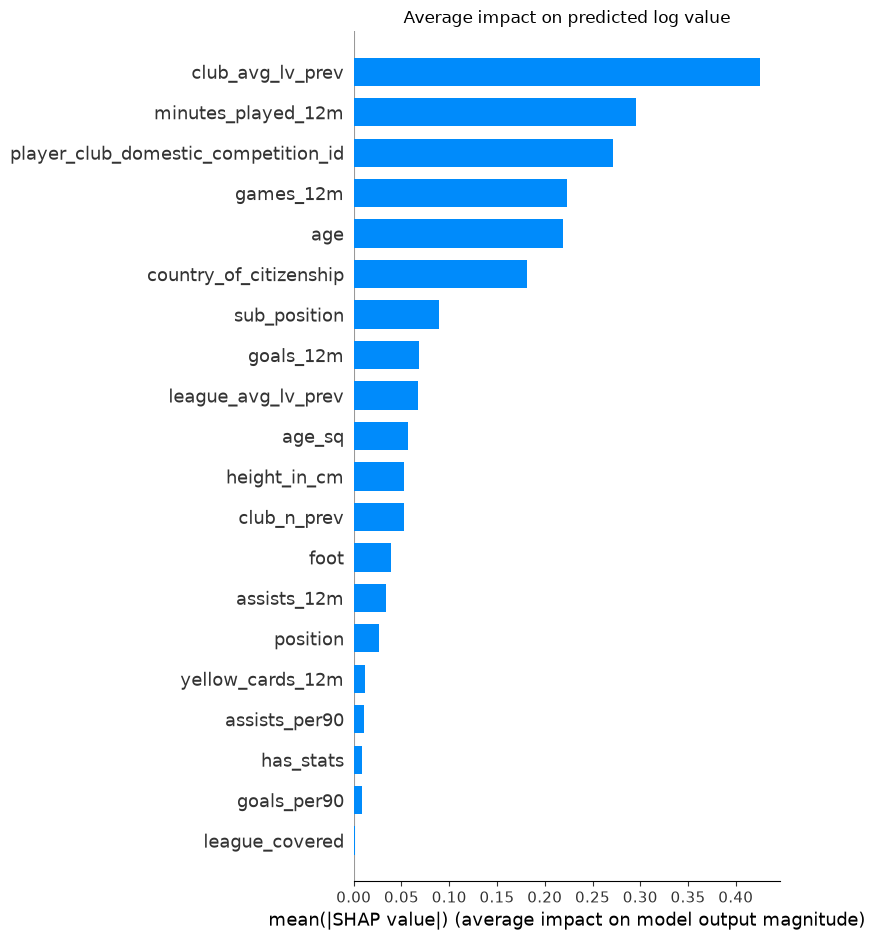

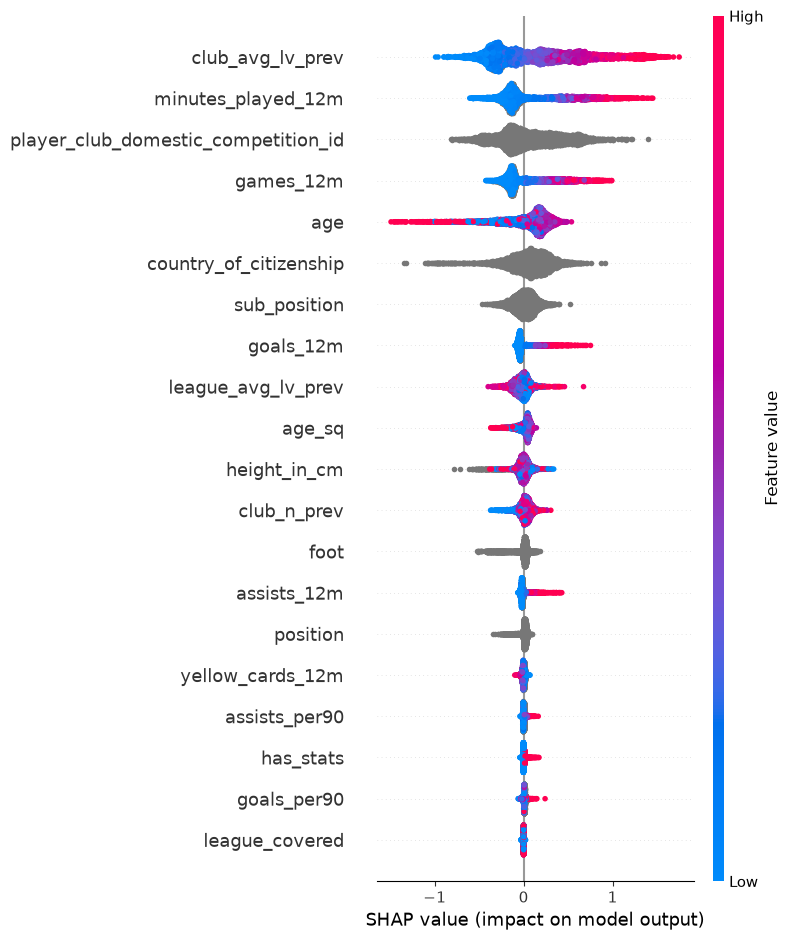

In [2]:
import os
os.makedirs("../reports", exist_ok=True)

# Explaining a sample of 5,000 rows because SHAP on all test rows would be slow
sample = Xte.sample(5000, random_state=42)
sv = shap.TreeExplainer(model).shap_values(sample)

shap.summary_plot(sv, sample, plot_type="bar", show=False)
plt.title("Average impact on predicted log value")
plt.tight_layout()
plt.savefig("../reports/shap_importance.png", dpi=150)
plt.show()

shap.summary_plot(sv, sample, show=False)  # each dot is one player; colour shows the feature's value
plt.tight_layout()
plt.savefig("../reports/shap_beeswarm.png", dpi=150)
plt.show()

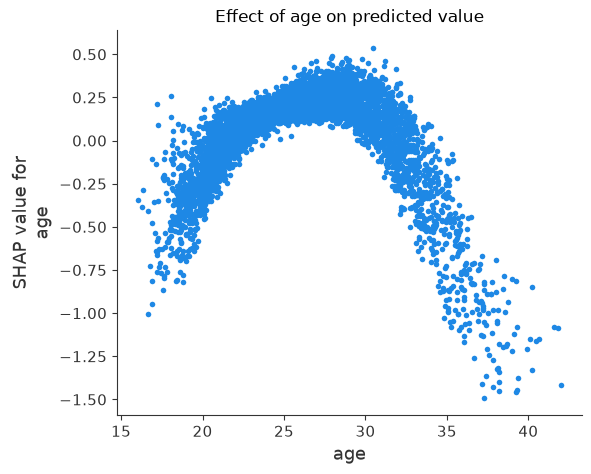

In [3]:
shap.dependence_plot("age", sv, sample, interaction_index=None, show=False)
plt.title("Effect of age on predicted value")
plt.savefig("../reports/shap_age.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
test["abs_pct_err"] = test["pct_err"].abs()
test["value_bucket"] = pd.cut(test["market_value_in_eur"], [0, 2.5e5, 1e6, 5e6, 2e7, 1e9],
                              labels=["<250k", "250k-1M", "1-5M", "5-20M", "20M+"])
test["age_group"] = pd.cut(test["age"], [14, 20, 23, 27, 31, 43],
                           labels=["15-20", "21-23", "24-27", "28-31", "32+"])

def summarize(by):
    # mean_log_err > 0 means overpredicting, < 0 means underpredicting
    return (test.groupby(by, observed=True)
            .agg(rows=("abs_pct_err", "size"),
                 median_abs_pct_err=("abs_pct_err", "median"),
                 mean_log_err=("err_log", "mean"))
            .round(2))

for col in ["value_bucket", "age_group", "position"]:
    print(summarize(col), "\n")

               rows  median_abs_pct_err  mean_log_err
value_bucket                                         
<250k         16123               66.86          0.57
250k-1M       25522               36.54          0.04
1-5M          16097               41.16         -0.30
5-20M          6233               41.35         -0.40
20M+           2329               28.61         -0.28 

            rows  median_abs_pct_err  mean_log_err
age_group                                         
15-20       5656               55.57         -0.20
21-23      14308               48.02         -0.05
24-27      20739               39.05          0.01
28-31      15391               37.28          0.09
32+        10210               40.79          0.23 

             rows  median_abs_pct_err  mean_log_err
position                                           
Attack      18545               43.62          0.03
Defender    21758               39.65          0.02
Goalkeeper   6779               47.77          0.05
M

In [5]:
names = pd.read_csv("../data/raw/players.csv", usecols=["player_id", "name"])
test = test.merge(names, on="player_id", how="left")

cols = ["name", "date", "age", "market_value_in_eur", "pred", "minutes_played_12m"]
big = test[test["market_value_in_eur"] >= 5e6]  # focusing on players worth 5M+, where misses matter most

print("Biggest underpredictions:")
print(big.nsmallest(10, "pct_err")[cols].round(0).to_string(index=False))
print("\nBiggest overpredictions:")
print(big.nlargest(10, "pct_err")[cols].round(0).to_string(index=False))

Biggest underpredictions:
             name       date  age  market_value_in_eur     pred  minutes_played_12m
   James Trafford 2025-03-28 22.0             20000000 286464.0                 0.0
    Marcel Reguła 2026-06-04 20.0              7000000 105060.0                 NaN
    Marcel Reguła 2026-03-26 19.0              7000000 110029.0                 NaN
   James Trafford 2025-05-27 23.0             22000000 351607.0                 0.0
      Love Arrhov 2025-11-19 18.0              5000000  80052.0                 NaN
Takehiro Tomiyasu 2025-10-21 27.0             16000000 281466.0                 NaN
       Jair Cunha 2025-06-06 20.0             13000000 295369.0                 NaN
    Junior Kroupi 2025-06-02 19.0             15000000 375720.0                 0.0
    Marcel Reguła 2025-12-08 19.0              5000000 133903.0                 NaN
 Christian Kofane 2025-06-24 19.0              5000000 135518.0                 NaN

Biggest overpredictions:
           name       da

C:\Users\Admin\AppData\Local\Temp\ipykernel_3316\2891579004.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(big.nsmallest(10, "pct_err")[cols].round(0).to_string(index=False))
C:\Users\Admin\AppData\Local\Temp\ipykernel_3316\2891579004.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(big.nlargest(10, "pct_err")[cols].round(0).to_string(index=False))
